In [1]:
import numpy as np 

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r"C:\Users\HASNA\Downloads\social_media_engagement_5000.csv")

In [4]:
print("shape:", df.shape)
df.head()

shape: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
print(df.dtypes)
df.info()

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type    

In [6]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y", errors="coerce")

In [8]:
print(df["posted_at"].head())
print(df["posted_at"].dtype)  

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[ns]
datetime64[ns]


In [9]:
for c in ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]:
    df[c] = df[c].astype("category")


In [10]:
print(df[["gender", "country", "post_type", "post_category", "device_type", "sentiment"]].dtypes)

gender           category
country          category
post_type        category
post_category    category
device_type      category
sentiment        category
dtype: object


In [11]:
likes = df["likes"].to_numpy(dtype=float)
impressions = df["impression_count"].to_numpy()
watch = df["watch_time_sec"].to_numpy()

In [12]:
print("Shape / dtype      :", likes.shape, likes.dtype)
print("Mean likes         :", np.nanmean(likes))
print("Median likes       :", np.nanmedian(likes))
print("Std likes          :", np.nanstd(likes))


Shape / dtype      : (5000,) float64
Mean likes         : 10107.043711340206
Median likes       : 10105.5
Std likes          : 5789.222332204695


In [13]:
print(df.isnull().sum())
print((df.isna().mean() * 100).round(2))

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
user_id             0.0
age                 3.0
gender              3.0
country             0.0
post_id             0.0
post_type           0.0
post_category       0.0
likes               3.0
comments            3.0
shares              3.0
watch_time_sec      0.0
impression_count    0.0
posted_at           0.0
follower_count      0.0
is_verified         0.0
device_type         0.0
sentiment           3.0
hashtags            0.0
engagement_rate     0.0
dtype: float64


In [14]:
clean = df.copy()

In [15]:
for c in ["likes", "comments", "shares"]:
    clean[c] = clean[c].fillna(clean[c].median())
clean["age"] = clean["age"].fillna(clean["age"].median()).astype(int)


print(clean.isnull().sum())

user_id               0
age                   0
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes                 0
comments              0
shares                0
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [16]:
df_dropna = df.dropna()
print("Rows before:", len(df), "| after dropna:", len(df_dropna))


Rows before: 5000 | after dropna: 4162


In [17]:
sorted_df = df.sort_values("posted_at")
likes_ffill = sorted_df["likes"].ffill()
likes_bfill = sorted_df["likes"].bfill()
print("Missing likes after ffill:", likes_ffill.isna().sum())
print("Missing likes after bfill:", likes_bfill.isna().sum())

Missing likes after ffill: 0
Missing likes after bfill: 0


In [18]:
print("Fully duplicated rows :", clean.duplicated().sum())
print("Duplicate post_id     :", clean["post_id"].duplicated().sum())
print("Duplicate user_id     :", clean["user_id"].duplicated().sum(), "(kept: a user can post many times)")

before = len(clean)
clean = clean.drop_duplicates()
clean = clean.drop_duplicates(subset="post_id", keep="first")
print(f"Rows: {before} -> {len(clean)}")

Fully duplicated rows : 0
Duplicate post_id     : 9
Duplicate user_id     : 138 (kept: a user can post many times)
Rows: 5000 -> 4991


In [19]:
for c in ["likes", "comments", "shares"]:
    clean[c] = clean[c].astype(int)

clean["age"] = clean["age"].astype(int)
clean["is_verified"] = clean["is_verified"].astype(bool)
print(clean.dtypes)

user_id                      int64
age                          int32
gender                    category
country                   category
post_id                      int64
post_type                 category
post_category             category
likes                        int32
comments                     int32
shares                       int32
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type               category
sentiment                 category
hashtags                    object
engagement_rate            float64
dtype: object


In [20]:
for c in ["gender", "country", "post_type", "post_category", "device_type"]:
    clean[c] = clean[c].astype(str).str.strip().str.title()


In [21]:
print(clean["gender"].value_counts())

gender
Male      1692
Other     1581
Female    1568
Nan        150
Name: count, dtype: int64


In [23]:
for c in ["likes", "comments", "shares"]:
    print(c, "negative values:", (clean[c] < 0).sum())
    clean[c] = clean[c].clip(lower=0)

likes negative values: 0
comments negative values: 0
shares negative values: 0


In [24]:
clean["hashtag_count"] = clean["hashtags"].fillna("").str.split().str.len()
print(clean[["hashtags", "hashtag_count"]].head())
print(clean["hashtag_count"].value_counts().sort_index())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1
hashtag_count
1    1652
2    1692
3    1647
Name: count, dtype: int64


In [26]:
clean["sentiment"] = (clean["sentiment"].astype(str)
                      .str.strip().str.lower()
                      .replace({"nan": "neutral", "": "neutral"}))

In [27]:
print(clean["sentiment"].value_counts())

sentiment
positive    2358
neutral     1675
negative     958
Name: count, dtype: int64


In [28]:
print("First 5 rows:")
display(clean.head())

First 5 rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,negative,#travel,2.777372,1


In [29]:
print("\nLast 5 rows:")
display(clean.tail())



Last 5 rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,positive,#travel #fun,0.466761,2
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,negative,#foodie #reels,0.621155,2
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [32]:
print("Columns:", clean.shape[1])
print("\nColumn names:")
print(clean.columns)
print(list(clean.columns))

Columns: 20

Column names:
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [33]:
print("\nDataset info:")
clean.info()


Dataset info:
<class 'pandas.core.frame.DataFrame'>
Index: 4991 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           4991 non-null   int64         
 1   age               4991 non-null   int32         
 2   gender            4991 non-null   object        
 3   country           4991 non-null   object        
 4   post_id           4991 non-null   int64         
 5   post_type         4991 non-null   object        
 6   post_category     4991 non-null   object        
 7   likes             4991 non-null   int32         
 8   comments          4991 non-null   int32         
 9   shares            4991 non-null   int32         
 10  watch_time_sec    4991 non-null   int64         
 11  impression_count  4991 non-null   int64         
 12  posted_at         4991 non-null   datetime64[ns]
 13  follower_count    4991 non-null   int64         
 14  is_verified   

In [34]:
print("Data types:")
print(clean.dtypes)

Data types:
user_id                      int64
age                          int32
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                        int32
comments                     int32
shares                       int32
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
dtype: object


In [35]:
display(clean.describe())

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991,4991.000000,4991.000000,4991.000000
mean,54547.943699,38.439591,547854.825486,10105.831897,1501.511921,1002.897015,4015.120617,50029.706872,2022-12-28 10:38:12.286115072,393904.683631,0.964971,1.998998
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32281.000000,26.000000,322410.000000,5224.500000,791.000000,511.000000,2023.500000,24997.000000,2022-07-03 12:00:00,195064.500000,0.145709,1.000000
50%,54327.000000,38.000000,547905.000000,10105.000000,1497.000000,1012.000000,4034.000000,49954.000000,2022-12-27 00:00:00,389040.000000,0.253806,2.000000
75%,77172.500000,51.000000,771256.500000,14965.000000,2234.500000,1482.500000,6020.500000,74715.500000,2023-06-27 12:00:00,589869.000000,0.504695,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26094.658996,14.686923,260657.341322,5703.628075,856.683226,570.842898,2307.053146,28845.669265,NaN,230898.849565,5.322732,0.813094


In [36]:
display(clean.describe(include=["object", "category"]))


,gender,country,post_type,post_category,device_type,sentiment,hashtags
count,4991,4991,4991,4991,4991,4991,4991
unique,4,10,4,8,3,3,760
top,Male,India,Reel,Fitness,Mobile,positive,#tech
freq,1692,534,1281,674,1681,2358,201


In [37]:
display(clean.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,4991.0,NaN,NaN,NaN,54547.943699,10055.0,32281.0,54327.0,77172.5,99963.0,26094.658996
age,4991.0,NaN,NaN,NaN,38.439591,13.0,26.0,38.0,51.0,64.0,14.686923
gender,4991,4,Male,1692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,4991,10,India,534,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_id,4991.0,NaN,NaN,NaN,547854.825486,100068.0,322410.0,547905.0,771256.5,999455.0,260657.341322
post_type,4991,4,Reel,1281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_category,4991,8,Fitness,674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,4991.0,NaN,NaN,NaN,10105.831897,10.0,5224.5,10105.0,14965.0,19998.0,5703.628075
comments,4991.0,NaN,NaN,NaN,1501.511921,0.0,791.0,1497.0,2234.5,2999.0,856.683226
shares,4991.0,NaN,NaN,NaN,1002.897015,0.0,511.0,1012.0,1482.5,1999.0,570.842898


In [38]:
cat_cols = ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]

In [39]:
for c in cat_cols:
    print(f"--- {c} ---")
    print(clean[c].value_counts())
    print()

--- gender ---
gender
Male      1692
Other     1581
Female    1568
Nan        150
Name: count, dtype: int64

--- country ---
country
India        534
Canada       512
Brazil       504
Uae          502
Usa          501
France       496
Uk           491
Australia    490
Germany      489
Japan        472
Name: count, dtype: int64

--- post_type ---
post_type
Reel     1281
Image    1244
Text     1243
Video    1223
Name: count, dtype: int64

--- post_category ---
post_category
Fitness      674
Tech         665
Music        634
Education    630
Lifestyle    604
Travel       599
Fashion      593
Food         592
Name: count, dtype: int64

--- device_type ---
device_type
Mobile     1681
Desktop    1656
Tablet     1654
Name: count, dtype: int64

--- sentiment ---
sentiment
positive    2358
neutral     1675
negative     958
Name: count, dtype: int64



In [40]:
for c in cat_cols:
    print(c, "->", clean[c].unique())

gender -> ['Female' 'Male' 'Other' 'Nan']
country -> ['Brazil' 'Uk' 'France' 'Canada' 'Japan' 'Australia' 'India' 'Uae'
 'Germany' 'Usa']
post_type -> ['Image' 'Reel' 'Text' 'Video']
post_category -> ['Fitness' 'Food' 'Tech' 'Travel' 'Fashion' 'Lifestyle' 'Education'
 'Music']
device_type -> ['Mobile' 'Tablet' 'Desktop']
sentiment -> ['negative' 'positive' 'neutral']


In [41]:
print("\nNumber of unique values:")
print(clean[cat_cols].nunique())
print("Unique users:", clean["user_id"].nunique())
print("Unique posts:", clean["post_id"].nunique())


Number of unique values:
gender            4
country          10
post_type         4
post_category     8
device_type       3
sentiment         3
dtype: int64
Unique users: 4854
Unique posts: 4991


In [42]:
num_cols = ["age", "likes", "comments", "shares", "watch_time_sec",
            "impression_count", "follower_count", "engagement_rate"]

corr = clean[num_cols].corr()
display(corr.round(3))

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
age,1.000,-0.037,-0.008,0.013,0.005,0.014,-0.026,0.008
likes,-0.037,1.000,-0.019,0.005,0.008,0.007,-0.022,0.094
comments,-0.008,-0.019,1.000,0.005,-0.017,-0.009,-0.011,0.000
shares,0.013,0.005,0.005,1.000,0.014,-0.005,-0.011,0.022
watch_time_sec,0.005,0.008,-0.017,0.014,1.000,-0.005,0.004,-0.001
impression_count,0.014,0.007,-0.009,-0.005,-0.005,1.000,-0.015,-0.232
follower_count,-0.026,-0.022,-0.011,-0.011,0.004,-0.015,1.000,0.002
engagement_rate,0.008,0.094,0.000,0.022,-0.001,-0.232,0.002,1.000


In [43]:
print(clean.groupby("post_type")["likes"].mean().round(2))

post_type
Image    10103.13
Reel     10036.05
Text     10099.93
Video    10187.67
Name: likes, dtype: float64


In [44]:
print(clean.groupby("country")["impression_count"].agg(["sum", "mean"]).round(2))

                sum      mean
country                      
Australia  23727212  48422.88
Brazil     24793360  49193.17
Canada     24912123  48656.49
France     25656926  51727.67
Germany    23787459  48645.11
India      28056833  52540.89
Japan      23418816  49616.14
Uae        24565687  48935.63
Uk         25096651  51113.34
Usa        25683200  51263.87


In [45]:
region_df = pd.DataFrame({
    "country": ["Australia", "Brazil", "Canada", "France", "Germany",
                "India", "Japan", "UAE", "UK", "USA"],
    "region": ["Oceania", "South America", "North America", "Europe", "Europe",
               "Asia", "Asia", "Middle East", "Europe", "North America"]
})

In [46]:
wrangled = clean.merge(region_df, on="country", how="left")
print(wrangled[["country", "region"]].head())
print("Rows before/after merge:", len(clean), len(wrangled))


  country         region
0  Brazil  South America
1  Brazil  South America
2      Uk            NaN
3  France         Europe
4      Uk            NaN
Rows before/after merge: 4991 4991


In [47]:
lookup = region_df.set_index("country")
joined = clean.join(lookup, on="country")
print(joined["region"].isna().sum(), "rows with no region")

1494 rows with no region


In [48]:
first_half = wrangled.iloc[:2500]
second_half = wrangled.iloc[2500:]
stacked = pd.concat([first_half, second_half], axis=0, ignore_index=True)
print("Rows after concat (axis=0):", len(stacked))


Rows after concat (axis=0): 4991


In [49]:
wrangled["hashtag_count"] = wrangled["hashtags"].fillna("").str.split().str.len()


In [50]:
wrangled["engagement_score"] = (wrangled["likes"] * 1
                                + wrangled["comments"] * 2
                                + wrangled["shares"] * 3)

In [51]:
wrangled["engagement_per_1k"] = wrangled["engagement_score"] / wrangled["impression_count"] * 1000

In [53]:
for c in ["likes", "comments", "shares", "impression_count", "follower_count"]:
    wrangled[f"log_{c}"] = np.log1p(wrangled[c])

display(wrangled[["likes", "log_likes", "engagement_score", "engagement_per_1k", "hashtag_count"]].head())

,likes,log_likes,engagement_score,engagement_per_1k,hashtag_count
0,7011,8.855378,11190,250.615901,3
1,11750,9.371694,22383,279.034108,1
2,4862,8.489411,8415,187.591957,1
3,5350,8.585039,10663,151.344830,3
4,12682,9.448018,22052,3663.731517,1


In [54]:
by_type = wrangled.groupby("post_type").agg(
    posts=("post_id", "count"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_hashtags=("hashtag_count", "mean"),
).round(2)
display(by_type.sort_values("avg_engagement_score", ascending=False))

,posts,avg_likes,avg_comments,avg_shares,avg_engagement_score,avg_hashtags
post_type,,,,,,
Image,1244,10103.13,1524.81,1018.61,16208.59,2.03
Video,1223,10187.67,1479.57,997.69,16139.89,2.01
Text,1243,10099.93,1497.91,1013.04,16134.85,1.96
Reel,1281,10036.05,1503.33,982.77,15991.01,2.01


In [55]:
by_country = wrangled.groupby("country").agg(
    posts=("post_id", "count"),
    total_impressions=("impression_count", "sum"),
    avg_impressions=("impression_count", "mean"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_followers=("follower_count", "mean"),
).round(2)
display(by_country.sort_values("total_impressions", ascending=False))


,posts,total_impressions,avg_impressions,avg_engagement_score,avg_followers
country,,,,,
India,534,28056833,52540.89,16070.64,416297.86
Usa,501,25683200,51263.87,16023.69,387904.33
France,496,25656926,51727.67,16485.69,378857.87
Uk,491,25096651,51113.34,15791.88,378355.32
Canada,512,24912123,48656.49,16146.05,387647.39
Brazil,504,24793360,49193.17,15894.12,407251.34
Uae,502,24565687,48935.63,16285.24,402048.66
Germany,489,23787459,48645.11,16103.40,397135.43
Australia,490,23727212,48422.88,16347.12,390641.30


In [56]:
by_sent = wrangled.groupby("sentiment").agg(
    posts=("post_id", "count"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_engagement_score=("engagement_score", "mean"),
).round(2)
display(by_sent)

,posts,avg_likes,avg_comments,avg_shares,avg_engagement_score
sentiment,,,,,
negative,958,10208.04,1514.57,1006.06,16255.36
neutral,1675,9974.61,1521.43,1002.09,16023.74
positive,2358,10157.52,1482.06,1002.19,16128.20


In [57]:
display(wrangled.groupby(["post_type", "sentiment"])["engagement_score"].mean().unstack().round(1))

sentiment,negative,neutral,positive
post_type,,,
Image,15985.5,16083.2,16384.2
Reel,16662.5,16040.6,15674.6
Text,16022.5,15981.0,16296.9
Video,16294.7,15987.1,16174.7


In [58]:
cols = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]
data = wrangled[cols]

In [59]:
central = pd.DataFrame({
    "mean": data.mean(),
    "median": data.median(),
    "mode": data.mode().iloc[0],
}).round(3)
display(central)

,mean,median,mode
likes,10105.832,10105.000,10105.000
comments,1501.512,1497.000,1497.000
shares,1002.897,1012.000,1012.000
watch_time_sec,4015.121,4034.000,916.000
engagement_rate,0.965,0.254,0.006
follower_count,393904.684,389040.000,497502.000


In [60]:
spread = pd.DataFrame({
    "std_dev": data.std(),
    "variance": data.var(),
    "min": data.min(),
    "max": data.max(),
    "range": data.max() - data.min(),
}).round(3)
display(spread)

,std_dev,variance,min,max,range
likes,5703.628,3.253137e+07,10.000,19998.000,19988.000
comments,856.683,7.339062e+05,0.000,2999.000,2999.000
shares,570.843,3.258616e+05,0.000,1999.000,1999.000
watch_time_sec,2307.053,5.322494e+06,0.000,7998.000,7998.000
engagement_rate,5.323,2.833100e+01,0.006,191.504,191.498
follower_count,230898.850,5.331428e+10,87.000,799533.000,799446.000


In [61]:
percentiles = data.quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T
percentiles.columns = ["1%", "5%", "10%", "25%", "50%", "75%", "90%", "95%", "99%"]
display(percentiles.round(3))

,1%,5%,10%,25%,50%,75%,90%,95%,99%
likes,227.900,1090.000,2184.000,5224.500,10105.000,14965.000,18016.000,19096.000,19857.200
comments,29.000,155.000,303.000,791.000,1497.000,2234.500,2696.000,2861.000,2975.100
shares,21.900,102.500,205.000,511.000,1012.000,1482.500,1796.000,1901.500,1983.000
watch_time_sec,71.900,396.500,783.000,2023.500,4034.000,6020.500,7212.000,7577.500,7924.400
engagement_rate,0.033,0.059,0.084,0.146,0.254,0.505,1.201,2.332,13.715
follower_count,7162.300,40807.500,76458.000,195064.500,389040.000,589869.000,717827.000,760573.500,792567.000


In [64]:
import matplotlib.pyplot as plt

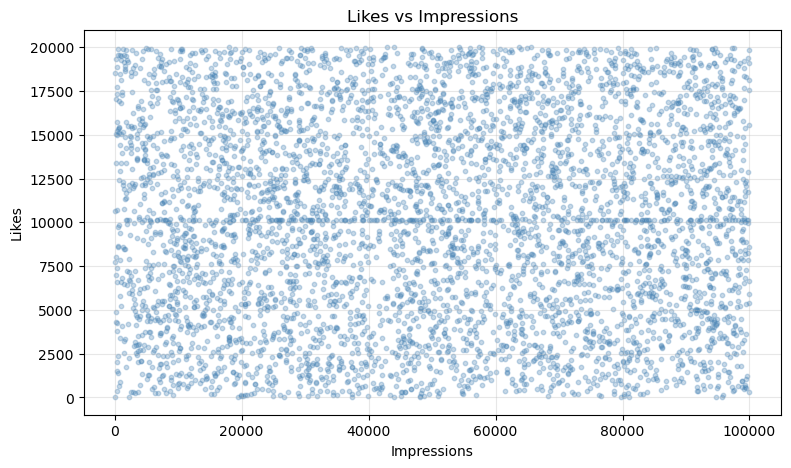

In [66]:
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

plt.scatter(wrangled["impression_count"], wrangled["likes"], alpha=0.3, s=10, color="steelblue")
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.show()

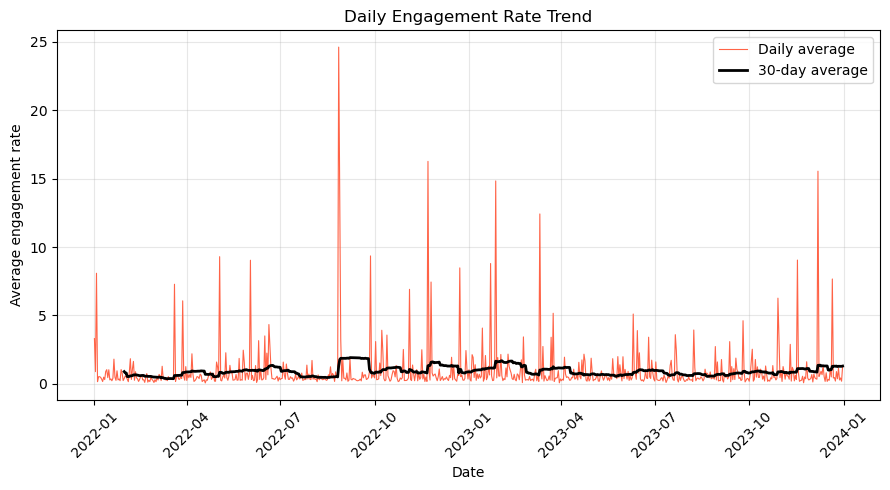

In [67]:
daily = wrangled.groupby("posted_at")["engagement_rate"].mean()

plt.plot(daily.index, daily.values, color="tomato", linewidth=0.8, label="Daily average")
plt.plot(daily.index, daily.rolling(30).mean(), color="black", linewidth=2, label="30-day average")
plt.title("Daily Engagement Rate Trend")
plt.xlabel("Date")
plt.ylabel("Average engagement rate")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

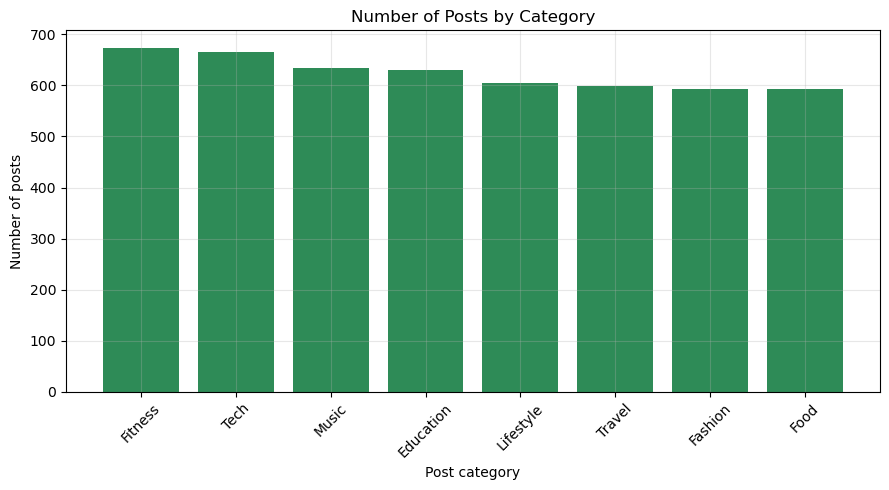

In [68]:
cat_counts = wrangled["post_category"].value_counts()

plt.bar(cat_counts.index, cat_counts.values, color="seagreen")
plt.title("Number of Posts by Category")
plt.xlabel("Post category")
plt.ylabel("Number of posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

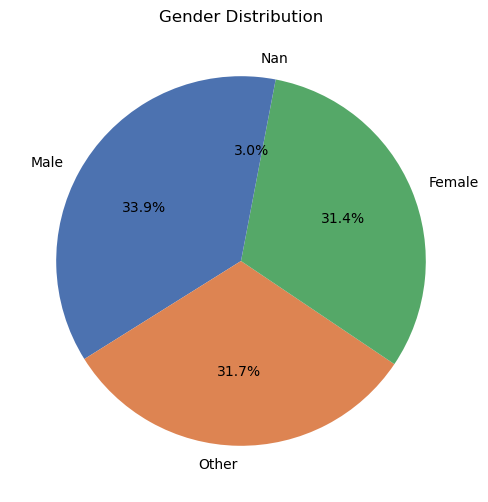

In [69]:
gender_counts = wrangled["gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%",
        startangle=90, colors=["#4c72b0", "#dd8452", "#55a868"])
plt.title("Gender Distribution")
plt.show()

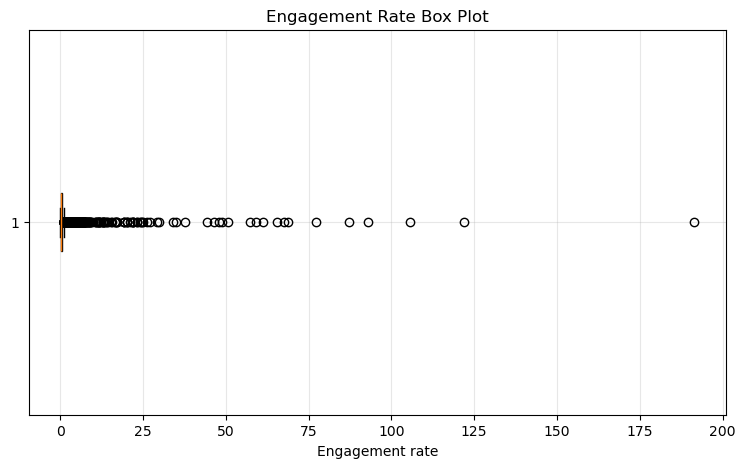

In [70]:
plt.boxplot(wrangled["engagement_rate"], vert=False, patch_artist=True,
            boxprops=dict(facecolor="lightblue"))
plt.title("Engagement Rate Box Plot")
plt.xlabel("Engagement rate")
plt.show()

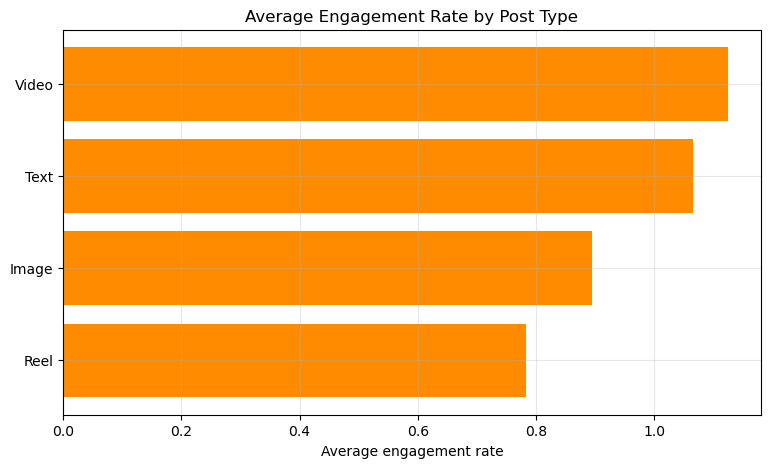

In [71]:
avg_type = wrangled.groupby("post_type")["engagement_rate"].mean().sort_values()

plt.barh(avg_type.index, avg_type.values, color="darkorange")
plt.title("Average Engagement Rate by Post Type")
plt.xlabel("Average engagement rate")
plt.show()

In [72]:
import seaborn as sns

In [73]:
sns.set_theme(style="whitegrid")

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27952\1588429129.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=wrangled, x="post_type", order=wrangled["post_type"].value_counts().index, palette="viridis")


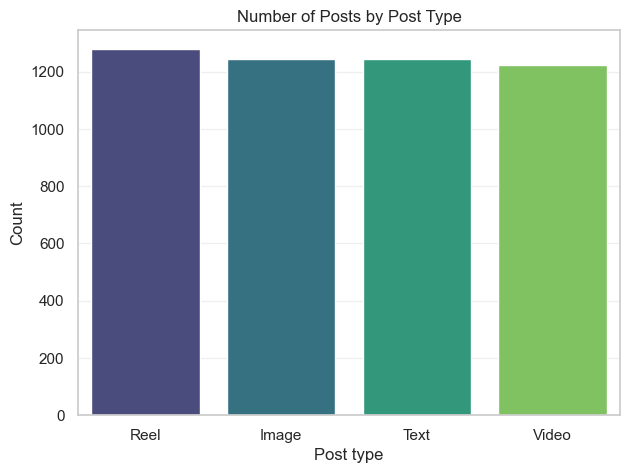

In [74]:
plt.figure(figsize=(7, 5))
sns.countplot(data=wrangled, x="post_type", order=wrangled["post_type"].value_counts().index, palette="viridis")
plt.title("Number of Posts by Post Type")
plt.xlabel("Post type")
plt.ylabel("Count")
plt.show()

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27952\2281826045.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=wrangled, x="post_category", y="likes", estimator="mean", errorbar=None, palette="mako")


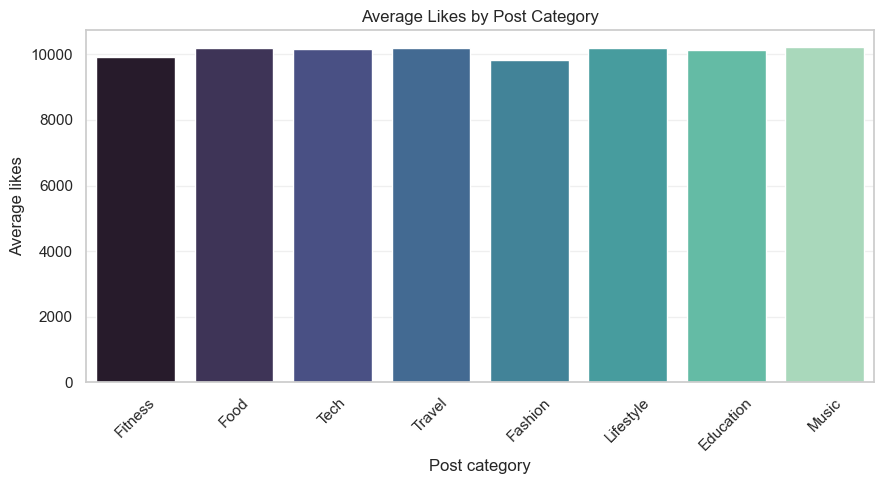

In [75]:
plt.figure(figsize=(9, 5))
sns.barplot(data=wrangled, x="post_category", y="likes", estimator="mean", errorbar=None, palette="mako")
plt.title("Average Likes by Post Category")
plt.xlabel("Post category")
plt.ylabel("Average likes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27952\1099940218.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=wrangled, x="sentiment", y="follower_count", palette="Set2")


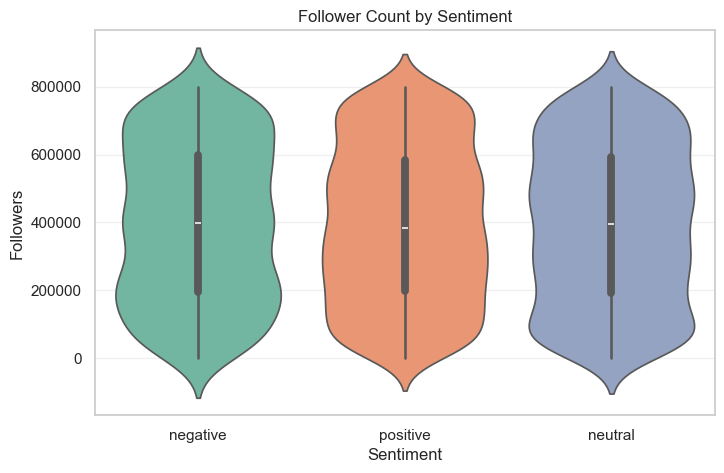

In [76]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=wrangled, x="sentiment", y="follower_count", palette="Set2")
plt.title("Follower Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Followers")
plt.show()

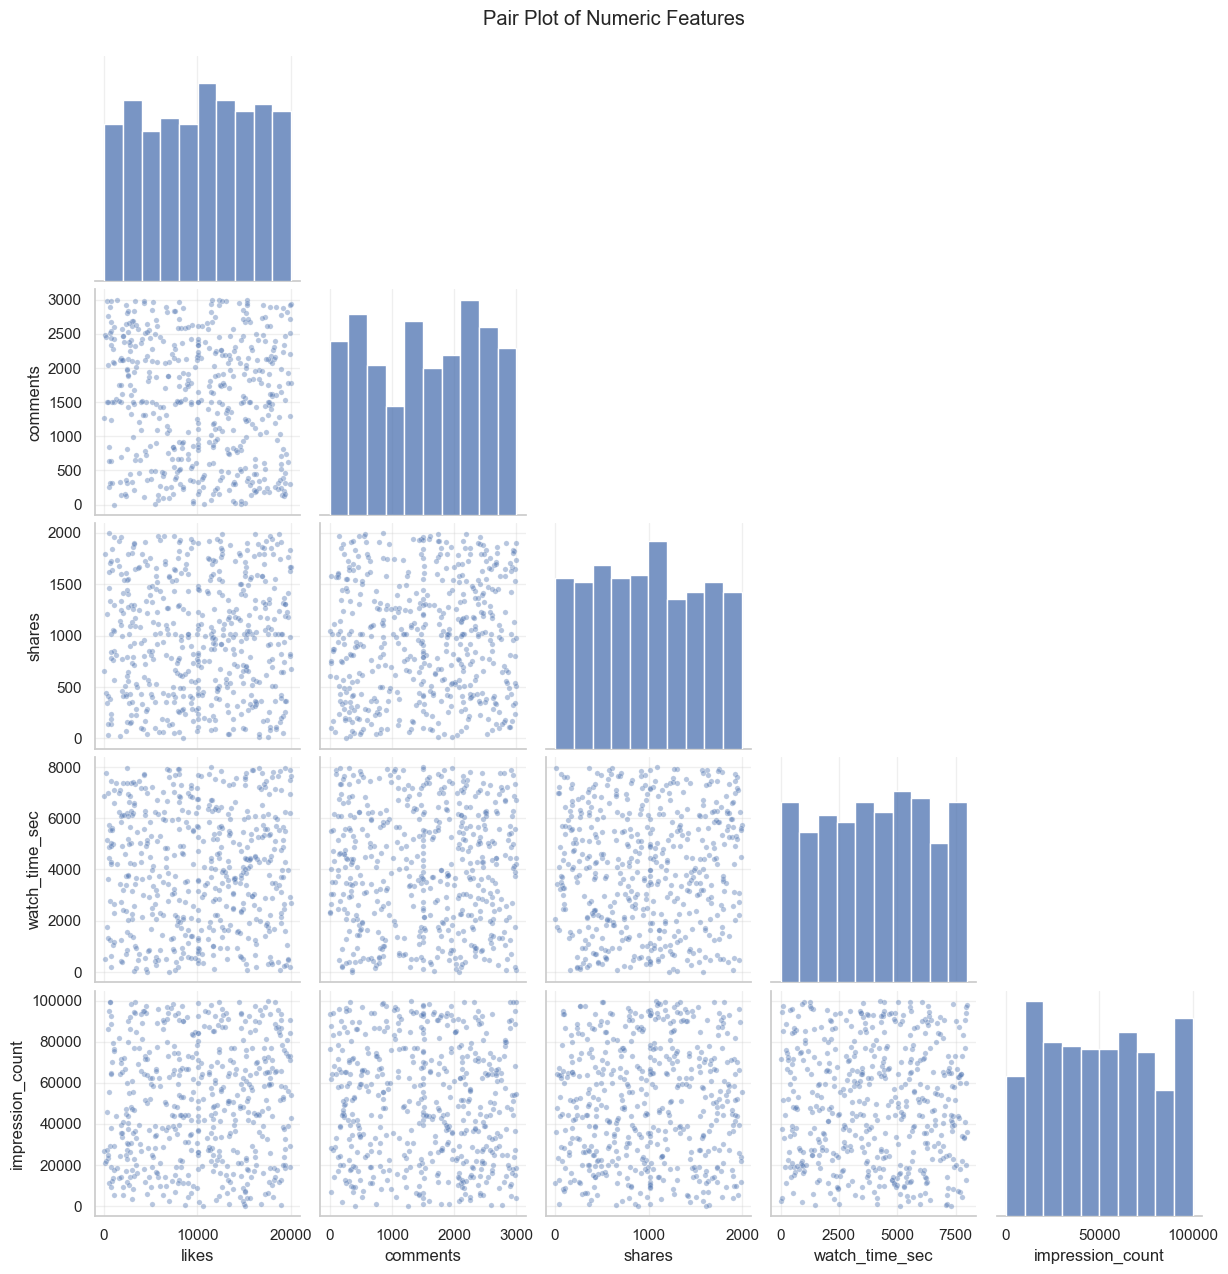

In [77]:
num_cols = ["likes", "comments", "shares", "watch_time_sec", "impression_count"]
sample = wrangled[num_cols].sample(500, random_state=42)

sns.pairplot(sample, corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Pair Plot of Numeric Features", y=1.02)
plt.show()

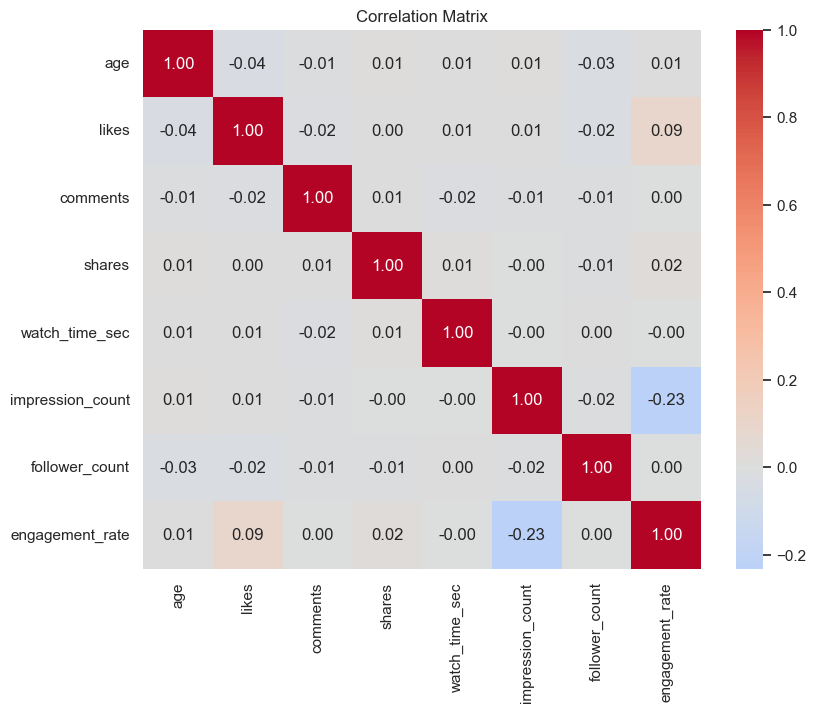

In [78]:
corr_cols = ["age", "likes", "comments", "shares", "watch_time_sec",
             "impression_count", "follower_count", "engagement_rate"]

plt.figure(figsize=(9, 7))
sns.heatmap(wrangled[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27952\3128873696.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=sample, x="device_type", y="engagement_rate", size=3, palette="Set1")
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 61.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 57.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\ProgramData\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 58.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, 

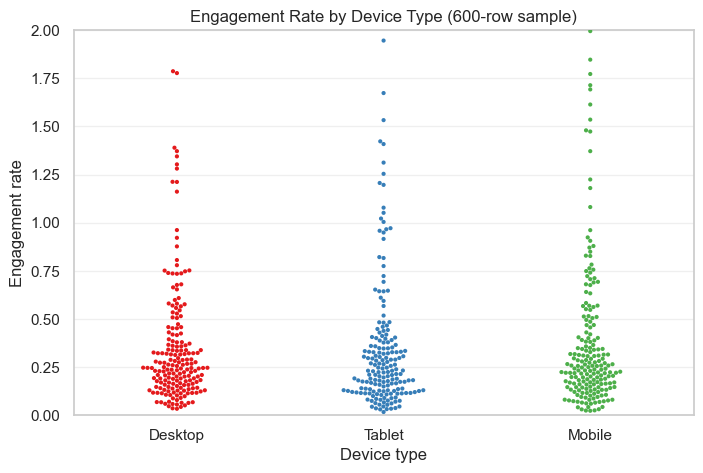

In [79]:
sample = wrangled.sample(600, random_state=1)

plt.figure(figsize=(8, 5))
sns.swarmplot(data=sample, x="device_type", y="engagement_rate", size=3, palette="Set1")
plt.title("Engagement Rate by Device Type (600-row sample)")
plt.xlabel("Device type")
plt.ylabel("Engagement rate")
plt.ylim(0, 2)
plt.show()

In [80]:
import plotly.express as px

In [81]:
daily = wrangled.groupby("posted_at", as_index=False)["engagement_rate"].mean()


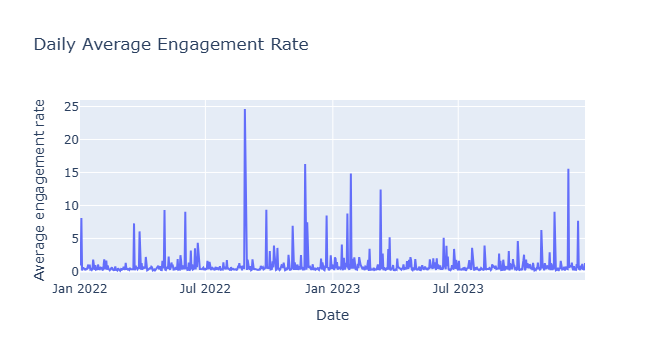

In [82]:
fig = px.line(daily, x="posted_at", y="engagement_rate", title="Daily Average Engagement Rate")
fig.update_layout(xaxis_title="Date", yaxis_title="Average engagement rate")
fig.show()

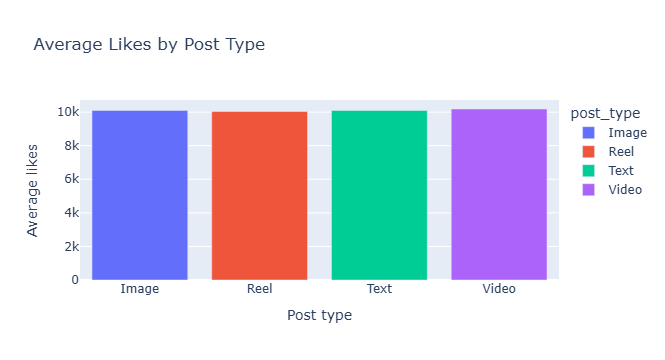

In [83]:
avg = wrangled.groupby("post_type", as_index=False)["likes"].mean()

fig = px.bar(avg, x="post_type", y="likes", color="post_type", title="Average Likes by Post Type")
fig.update_layout(xaxis_title="Post type", yaxis_title="Average likes")
fig.show()

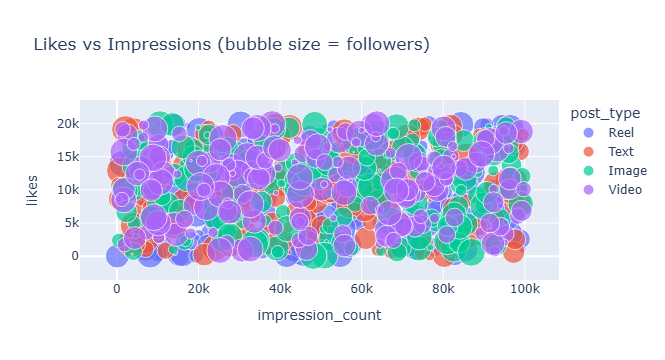

In [84]:
sample = wrangled.sample(800, random_state=3)

fig = px.scatter(sample, x="impression_count", y="likes",
                 size="follower_count", color="post_type",
                 hover_data=["country", "post_category"],
                 title="Likes vs Impressions (bubble size = followers)")
fig.show()

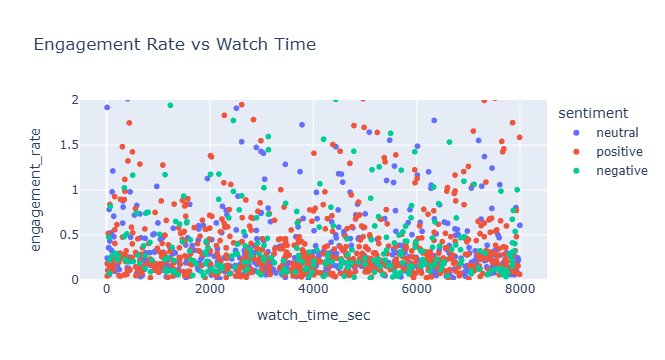

In [85]:
fig = px.scatter(wrangled.sample(1500, random_state=5),
                 x="watch_time_sec", y="engagement_rate", color="sentiment",
                 hover_data=["country", "device_type"],
                 title="Engagement Rate vs Watch Time")
fig.update_yaxes(range=[0, 2])
fig.show()

In [86]:
by_type = (df.groupby("post_type")["engagement_rate"]
             .agg(["mean", "median", "count"])
             .sort_values("median", ascending=False)
             .round(4))
display(by_type)

print("Highest engagement post type (median):", by_type.index[0])
print("Highest engagement post type (mean)  :", by_type["mean"].idxmax())

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27952\1285486706.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,mean,median,count
post_type,,,
image,0.8956,0.2644,1247
text,1.0645,0.2549,1245
reel,0.7830,0.2476,1283
video,1.1224,0.2470,1225


Highest engagement post type (median): image
Highest engagement post type (mean)  : video


In [89]:
by_cat = (df.groupby("post_category", observed=False)["engagement_rate"]
            .agg(["mean", "median", "count"])
            .sort_values("median", ascending=False)
            .round(4))
display(by_cat)

print("Best category (median):", by_cat.index[0])
print("Best category (likes)  :", df.groupby("post_category", observed=False)["likes"].mean().idxmax())

,mean,median,count
post_category,,,
education,0.8442,0.2783,631
fashion,0.8071,0.2588,594
music,0.8888,0.2561,635
food,1.3586,0.2533,593
travel,0.7022,0.2509,600
tech,1.1605,0.2508,665
lifestyle,1.0910,0.2490,607
fitness,0.8656,0.2485,675


Best category (median): education
Best category (likes)  : food


In [92]:
df = wrangled.copy()
metric = "engagement_rate"

by_country = (df.groupby("country", observed=False)["engagement_rate"]
                .agg(["mean", "median"])
                .sort_values("mean", ascending=False)
                .round(4))
display(by_country)

print("Top country:", by_country.index[0])

,mean,median
country,,
Brazil,1.5407,0.2483
Australia,1.3269,0.2696
France,1.1464,0.2426
Uae,1.1141,0.2732
Canada,0.9181,0.2641
Uk,0.8514,0.2411
Japan,0.7696,0.2617
Germany,0.7594,0.2680
India,0.6555,0.2447


Top country: Brazil


In [93]:
by_country = df.groupby("country")[metric].agg(["mean", "median"]).sort_values("mean", ascending=False).round(4)
display(by_country)
print("Top country:", by_country.index[0])

,mean,median
country,,
Brazil,1.5407,0.2483
Australia,1.3269,0.2696
France,1.1464,0.2426
Uae,1.1141,0.2732
Canada,0.9181,0.2641
Uk,0.8514,0.2411
Japan,0.7696,0.2617
Germany,0.7594,0.2680
India,0.6555,0.2447


Top country: Brazil


,engagement_rate,likes,comments,shares
age_group,,,,
13-17,0.862,10616.734,1494.634,993.375
18-24,1.039,10033.979,1505.819,974.735
25-34,0.811,10364.283,1504.798,997.282
35-44,0.957,10145.255,1515.615,1016.262
45-54,1.204,9975.039,1511.421,1016.602
55-64,0.899,9717.732,1471.958,1003.387


Correlation age vs engagement: 0.008


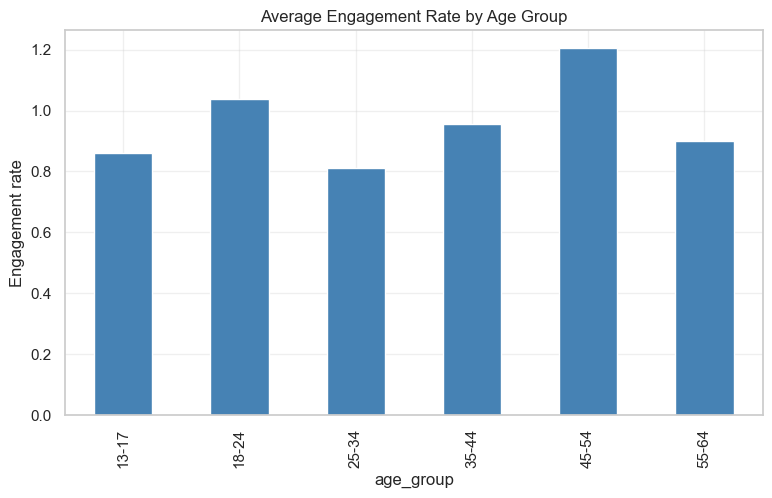

In [94]:
df["age_group"] = pd.cut(df["age"], bins=[12, 17, 24, 34, 44, 54, 64],
                         labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55-64"])
by_age = df.groupby("age_group", observed=True)[[metric, "likes", "comments", "shares"]].mean().round(3)
display(by_age)
print("Correlation age vs engagement:", round(df["age"].corr(df[metric]), 3))

by_age[metric].plot(kind="bar", color="steelblue", title="Average Engagement Rate by Age Group")
plt.ylabel("Engagement rate"); plt.show()

,engagement_rate,likes,comments,shares
age_group,,,,
13-17,0.862,10616.734,1494.634,993.375
18-24,1.039,10033.979,1505.819,974.735
25-34,0.811,10364.283,1504.798,997.282
35-44,0.957,10145.255,1515.615,1016.262
45-54,1.204,9975.039,1511.421,1016.602
55-64,0.899,9717.732,1471.958,1003.387


Correlation age vs engagement: 0.008


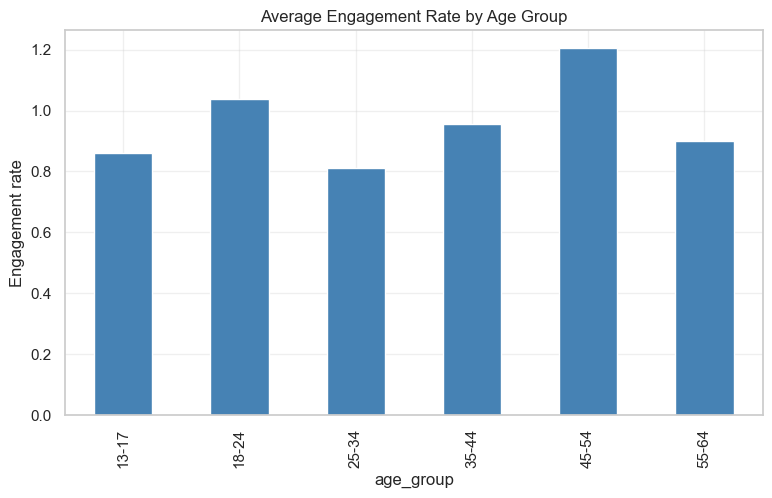

In [95]:
df["age_group"] = pd.cut(df["age"], bins=[12, 17, 24, 34, 44, 54, 64],
                         labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55-64"])
by_age = df.groupby("age_group", observed=True)[[metric, "likes", "comments", "shares"]].mean().round(3)
display(by_age)
print("Correlation age vs engagement:", round(df["age"].corr(df[metric]), 3))

by_age[metric].plot(kind="bar", color="steelblue", title="Average Engagement Rate by Age Group")
plt.ylabel("Engagement rate"); plt.show()

In [99]:
df = wrangled.copy()

df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce")

df["day_of_week"] = df["posted_at"].dt.day_name()
df["month"] = df["posted_at"].dt.month
df["year"] = df["posted_at"].dt.year

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df.groupby("day_of_week")["impression_count"].mean().reindex(order).round(0)
display(by_day)
print("Best day:", by_day.idxmax())





day_of_week
Monday       50013.0
Tuesday      51354.0
Wednesday    49914.0
Thursday     48118.0
Friday       49414.0
Saturday     50945.0
Sunday       50375.0
Name: impression_count, dtype: float64

Best day: Tuesday


In [100]:
dev = df.groupby("device_type")["watch_time_sec"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False).round(1)
display(dev)
print("Highest watch time:", dev.index[0])

,mean,median,count
device_type,,,
Mobile,4087.6,4110.0,1681
Tablet,3980.8,4072.0,1654
Desktop,3975.8,3922.0,1656


Highest watch time: Mobile


In [101]:
sent = df.groupby("sentiment").agg(
    posts=("post_id", "count"),
    share_of_posts=("post_id", lambda x: round(len(x) / len(df) * 100, 1)),
    avg_engagement_rate=(metric, "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_watch_time=("watch_time_sec", "mean"),
).round(3).sort_values("avg_engagement_rate", ascending=False)
display(sent)
print("Best sentiment:", sent.index[0])

,posts,share_of_posts,avg_engagement_rate,avg_likes,avg_comments,avg_shares,avg_watch_time
sentiment,,,,,,,
negative,958,19.2,1.040,10208.042,1514.574,1006.055,4055.649
positive,2358,47.2,0.956,10157.517,1482.057,1002.188,3983.332
neutral,1675,33.6,0.935,9974.613,1521.429,1002.089,4036.691


Best sentiment: negative


post_type,Image,Reel,Text,Video
sentiment,,,,
negative,0.714,1.281,1.091,1.035
neutral,1.088,0.564,0.695,1.437
positive,0.821,0.727,1.337,0.955


post_category,Education,Fashion,Fitness,Food,Lifestyle,Music,Tech,Travel
sentiment,,,,,,,,
negative,10030.0,10532.0,10813.0,10043.0,9861.0,10393.0,10118.0,9880.0
neutral,9564.0,9304.0,10137.0,10133.0,10280.0,9975.0,9753.0,10642.0
positive,10521.0,9912.0,9430.0,10341.0,10276.0,10326.0,10533.0,10018.0


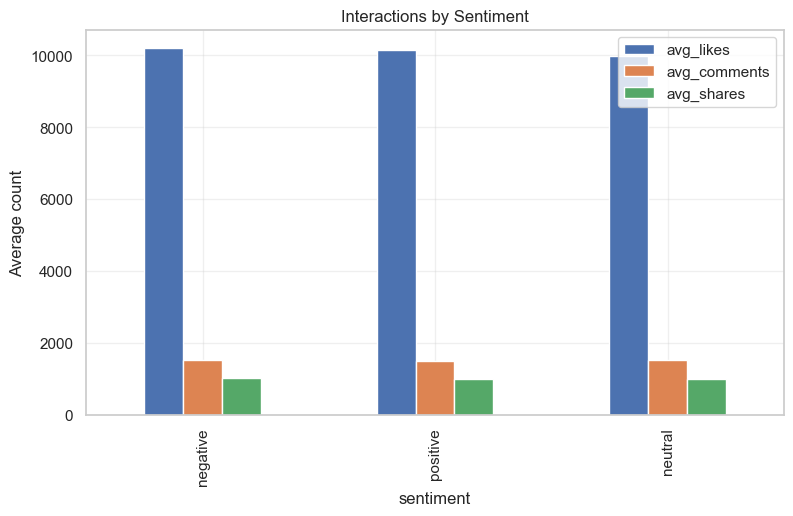

In [102]:
sent_type = df.pivot_table(index="sentiment", columns="post_type", values=metric, aggfunc="mean").round(3)
display(sent_type)

sent_cat = df.pivot_table(index="sentiment", columns="post_category", values="likes", aggfunc="mean").round(0)
display(sent_cat)

sent[["avg_likes", "avg_comments", "avg_shares"]].plot(kind="bar", title="Interactions by Sentiment")
plt.ylabel("Average count"); plt.show()